# Frente 1 — Formação: extensão vs. disciplinas da Poli

**PRO3201 — Estatística e Aplicações · Grupo 10 (J)**

**Pergunta da frente:** qual é o valor formativo que os alunos percebem na extensão, comparado às disciplinas obrigatórias, e como o perfil do grupo e a dedicação se associam a essa percepção?

### Como ler este notebook

- **Leia como um artigo.** As células de código só chamam funções com nomes autoexplicativos (em inglês, pela convenção do README) e mostram quais colunas são usadas. A lógica fica em `src/`:
  - `stats_tests.py`: testes da disciplina;
  - `regression.py`: regressão linear múltipla;
  - `formacao.py`: preparação dos dados;
  - `plotting/plots_formacao.py`: gráficos.
- **Basta ler textos, tabelas e gráficos.** Os quadros **"Conceito"** explicam cada método em poucas linhas.
- **Roteiro de cada pergunta (guia do grupo):**
  - **(a)** pergunta e hipóteses;
  - **(b)** teste e premissas;
  - **(c)** resultado;
  - **(d)** tabela ou gráfico;
  - **(e)** conclusão para o relatório.
- **Notação das tabelas:** as tabelas usam ponto decimal (padrão do Python). Um p-valor como `6.9e-12` significa 6,9 × 10⁻¹².
- **Arquivos exportados:** tabelas e figuras usam o prefixo `f1_`.
- **Perguntas cortadas:** P5, P7a e P8 do backlog original foram excluídas no alinhamento do grupo; P2 e P3 foram fundidas.

### Resumo dos achados

| Pergunta | Método | Resultado principal |
|---|---|---|
| **P1** Extensão × disciplinas | Teste t pareado | A extensão recebe em média **2,27 pontos a mais** (escala 1–5); 93% dão nota maior à extensão. |
| **P2+P3** Categoria do grupo × área do curso | Qui-quadrado + ANOVA de 2 fatores + Scheffé | As diferenças entre cursos parecem refletir, em boa parte, a **composição dos grupos**. Grupos técnicos têm ganho menor porque avaliam melhor as disciplinas. |
| **P4** Intensidade × tempo de casa | Qui-quadrado + ANOVA de 2 fatores | As **horas semanais** se associam ao preparo percebido: 85% de nota máxima acima de 20 h, contra 38% até 5 h. Não encontramos associação com o tempo de grupo. |
| **P6** Objetivo × importância da média | ANOVA de 1 fator + Scheffé | Quem mira **intercâmbio, iniciação científica ou desempenho** dá cerca de **1,2 ponto a mais** de importância à média do que quem foca no grupo ou no estágio. |
| **Regressão** Ganho líquido | Regressão linear múltipla + F parcial | O modelo final tem **categoria do grupo + horas**. Quem dedica o dobro de horas tem, em média, ganho **0,28 ponto maior**. É um modelo explicativo, útil para comparar perfis, não para prever alunos individuais. |

## 0. Preparação

*Célula técnica: só carrega as funções e os dados. Pode ser pulada na leitura.*

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR, TAB_DIR = ROOT_DIR / "data", ROOT_DIR / "output" / "figures", ROOT_DIR / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd

from src.formacao import (AREA_ORDER, CATEGORY_ORDER, DECOMPOSITION, FACTOR_LABELS, GOAL_CONTRASTS, GOAL_ORDER,
                          HOURS_ORDER, MAIN_SCALES, REGRESSION_BLOCKS, REGRESSION_LABELS, TIME_ORDER, build_scenarios,
                          check_data_quality, group_composition, hours_band_table, hours_share_by_category,
                          other_engineering_courses, prepare_front_data)
from src.plotting.plots_formacao import (plot_goal_means, plot_preparo_by_category_and_area,
                                         plot_preparo_distribution, plot_regression_scenarios,
                                         plot_residual_diagnostics, plot_top_score_share)
from src.regression import (backward_elimination, coefficient_table, coefficients_by_response, fit_ols,
                            joint_partial_f_test, model_summary, predict_scenarios)
from src.stats_tests import (bartlett_table, chi_square_association, chi_square_table, describe_scales,
                             group_means, group_means_for_outcomes, one_way_anova, paired_t_test, scheffe_contrasts,
                             scheffe_for_outcomes, two_way_anova, two_way_anova_for_outcomes)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
df = prepare_front_data(pd.read_parquet(DATA_DIR / "clean_data.parquet"))
print(f"Base carregada: {df.shape[0]} respondentes da Poli, todos participantes de grupos de extensão.")

Base carregada: 187 respondentes da Poli, todos participantes de grupos de extensão.


## 1. Dados e cuidados gerais

- **Base:** `clean_data.parquet` atualizado, enviado em 24/11, com 187 alunos da Poli. Só `objetivo_faculdade` tem valores ausentes (7 respostas livres que não puderam ser agrupadas), por isso a P6 usa n = 180.
- **Categorias de grupo** (tabela abaixo):
  - **Consultoria & Negócios:** Poli Júnior, Grupo de Negócios da Poli, Poli Consulting Club e Liga de Empreendedorismo;
  - **Engenharia:** Thunder Ratz e Poli Racing;
  - **Mercado Financeiro:** Poli Quant, Poli Real State e Poli Finance.

  A categoria original "Empreendedorismo" (só a Liga, n = 8) foi **somada a Consultoria & Negócios**. Há dois motivos: afinidade temática e a condição do teste qui-quadrado. Com 4 categorias, 30% das frequências esperadas ficariam abaixo de 5 e uma ficaria abaixo de 1, violando as duas regras do teste (verificado na célula abaixo). Com 3 categorias, ficam só 7%.
- **Escalas de 1 a 5 tratadas como numéricas.** O teste t, a ANOVA e a regressão comparam médias. Tratar uma escala Likert como numérica é prática usual com amostras deste tamanho.
- **Efeito teto:** 64% deram nota 5 ao preparo na extensão, e ninguém deu 1 ou 2. Por isso, a P4 também usa a variável "deu nota 5 ou não" (`preparo_ext_maximo`).
- **Ganho líquido** = preparo na extensão − preparo nas disciplinas (`delta_preparo`). Como a nota da extensão varia pouco, quem mais move o ganho é a nota das disciplinas. Sempre que o ganho varia, olhamos as duas partes separadamente.
- **Desenho do estudo:** todos os respondentes participam de extensão, e não há grupo de comparação. Os resultados descrevem **associações e percepções entre participantes**, e não efeitos causais.
- **Nível de significância:** α = 5% em todos os testes.

In [2]:
display(check_data_quality(df))
display(group_composition(df))
display(other_engineering_courses(df))
print("Qui-quadrado com as 4 categorias originais (para justificar a fusão de Empreendedorismo):")
chi_square_association(df, "categoria_extensao", "grande_area_curso")[1]

,Valores ausentes
preparo_extensao,0
preparo_disciplinas,0
delta_preparo,0
importancia_media,0
categoria_extensao,0
grande_area_curso,0
horas_semanais_grupo,0
tempo_grupo,0
objetivo_faculdade,7
tempo_deslocamento_num,0


n
Categoria do grupo     Grupo de extensão                   
Consultoria & Negócios Grupo de Negócios da Poli         15
                       Liga de Empreendedorismo da Poli   8
                       Poli Consulting Club              10
                       Poli Júnior                       75
Engenharia             Poli Racing                       16
                       Thunder Ratz                      29
Mercado Financeiro     Poli Finance                       9
                       Poli Quant                        13
                       Poli Real State                   12

Cursos em 'Outras Engenharias'
Engenharia de Materiais/Metalúrgica/Nuclear    12
Engenharia de Minas/Petróleo                    7
Engenharia Química                              2
Name: n, dtype: int64

Qui-quadrado com as 4 categorias originais (para justificar a fusão de Empreendedorismo):


,Teste de associação
Qui-quadrado (χ²),79.97
Graus de liberdade,12
p-valor,4.2e-12
"V de Cramér (0 = nenhuma, 1 = total)",0.378
Menor frequência esperada,0.9
% de caselas com esperado < 5,30%
Decisão (α = 5%),Rejeita H0


## 2. Diagnóstico descritivo

In [3]:
descriptive = describe_scales(df, MAIN_SCALES)
descriptive.to_csv(TAB_DIR / "f1_tab01_descritiva.csv")
descriptive

,n,Média,Desvio-padrão,Mínimo,1º quartil,Mediana,3º quartil,Máximo,% nota 5
Variável,,,,,,,,,
Preparo profissional na extensão (1–5),187,4.59,0.58,3,4.0,5.0,5.0,5,63.64
Preparo profissional nas disciplinas (1–5),187,2.32,0.95,1,2.0,2.0,3.0,4,0.00
Ganho líquido (extensão − disciplinas; de −4 a 4),187,2.27,1.17,-1,1.5,2.0,3.0,4,NaN
Importância da média ponderada (1–5),187,2.93,1.05,1,2.0,3.0,4.0,5,5.35


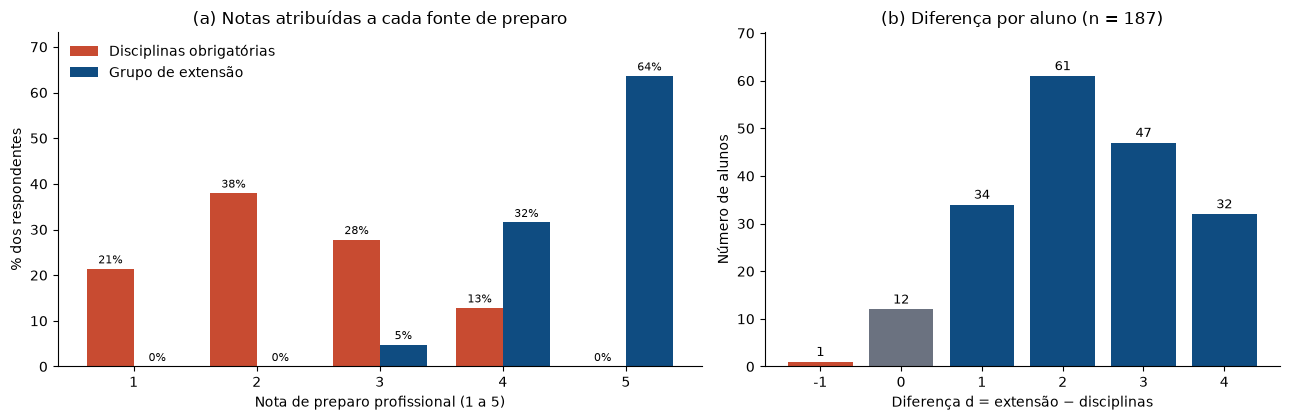

In [4]:
plot_preparo_distribution(df, FIG_DIR / "f1_fig01_preparo_extensao_vs_disciplinas.png")

**Leitura.**

- A extensão concentra notas 4 e 5 (média 4,59); as disciplinas concentram notas 1 a 3 (média 2,32).
- No gráfico (b), quase todos os alunos têm diferença positiva; só 1 aluno dá nota maior às disciplinas.
- A importância da média tem distribuição centrada (média 2,93) e mais espalhada.

## 3. P1 — A extensão prepara mais do que as disciplinas obrigatórias?

**(a) Pergunta e hipóteses.** Para cada aluno, seja $d$ = (nota de preparo na extensão) − (nota de preparo nas disciplinas), com média populacional $\mu_d$.

- $H_0$: $\mu_d = 0$ (em média, as duas fontes preparam igualmente);
- $H_1$: $\mu_d > 0$ (a extensão é percebida como mais preparatória).

**(b) Teste e premissas.** Teste t pareado unilateral. As premissas são duas:

- os pares são independentes entre si (um aluno por linha);
- a média das diferenças tem distribuição aproximadamente normal. Com n = 187, isso vale pelo Teorema Central do Limite, mesmo com $d$ assumindo poucos valores inteiros (gráfico 1b).

> **Conceito — teste t pareado.** Quando a mesma pessoa responde às duas perguntas, as notas não são independentes. Por isso, calcula-se a diferença de cada pessoa e testa-se se a média dessas diferenças é zero: $t = \bar d / (s_d/\sqrt{n})$, com $n-1$ graus de liberdade.
>
> O **d de Cohen** ($\bar d / s_d$) mede o tamanho do efeito em desvios-padrão: 0,2 é pequeno, 0,5 é médio e 0,8 é grande.

In [5]:
p1 = paired_t_test(df, "preparo_extensao", "preparo_disciplinas")
p1.to_csv(TAB_DIR / "f1_tab02_p1_teste_t_pareado.csv")
p1

,Teste t pareado
n (pares),187
Média de d,2.267
Desvio-padrão de d,1.165
IC 95% da média de d,[2.10; 2.44]
Estatística t,26.6
Graus de liberdade,186
p-valor,1.3e-65
Tamanho de efeito (d de Cohen = média de d / DP de d),1.95
% com d > 0 / d = 0 / d < 0,93.0% / 6.4% / 0.5%
Decisão (α = 5%),Rejeita H0


**(c) Resultado.**

- **Teste:** t(186) = 26,6, p ≈ 10⁻⁶⁵. Rejeita-se $H_0$.
- **Diferença média:** 2,27 pontos (IC 95%: 2,10 a 2,44).
- **Tamanho de efeito:** d de Cohen = 1,95, mais que o dobro do limiar de "efeito grande".
- **Distribuição:** 93,0% dão nota maior à extensão, 6,4% empatam e 0,5% (1 aluno) dão nota maior às disciplinas.
- **Subgrupos:** a média da diferença é positiva em todas as categorias de grupo e áreas de curso, sempre acima de 1,6 (tabelas da P2+P3).

**(d)** Figura `f1_fig01`, tabela `f1_tab02`.

**(e) Conclusão para o relatório.** Os participantes de grupos de extensão percebem um preparo profissional muito maior na extensão do que nas disciplinas obrigatórias: em média, 2,27 pontos a mais na escala de 1 a 5 (IC 95%: 2,10 a 2,44; t pareado, p < 0,001; d de Cohen = 1,95). A percepção é quase unânime: 93% favorecem a extensão e só 1 aluno favorece as disciplinas. Como todos os respondentes são de extensão, o resultado mede a percepção relativa desses alunos, e não um efeito causal da participação.

## 4. P2 + P3 — As diferenças vêm da área do curso ou da categoria do grupo?

**(a) Pergunta e hipóteses.** O ganho líquido muda conforme a área do curso? Ou essas diferenças acompanham a forma como cada área se distribui entre os grupos de extensão? A análise tem três etapas.

1. **Categoria e área são associadas?** Teste qui-quadrado de associação.
   - $H_0$: a categoria do grupo é independente da área do curso;
   - $H_1$: há associação.
2. **Qual fator se associa ao ganho?** ANOVA de 2 fatores (categoria + área), com F parcial para cada fator.
   - $H_0$: as médias do ganho são iguais entre os níveis do fator, dado o outro fator;
   - $H_1$: ao menos uma média difere.
   - A mesma análise é repetida para as duas partes do ganho (disciplinas e extensão).
3. **Quais categorias diferem?** Contrastes de Scheffé.

**(b) Premissas.**

- **Qui-quadrado:** no máximo 20% das caselas com frequência esperada abaixo de 5, e nenhuma abaixo de 1.
- **ANOVA:**
  - observações independentes;
  - resíduos aproximadamente normais (n grande);
  - variâncias homogêneas entre os grupos, verificadas pelo teste de Bartlett.
- **Interação:** a ANOVA é aditiva, sem o termo de interação, porque há combinações vazias. Nenhum aluno de Civil & Ambiental ou de Produção está em grupos de Engenharia, então não dá para estimar como categoria e área interagem.

> **Conceito — qui-quadrado de associação.** Compara as contagens observadas de cada combinação (categoria × área) com as contagens esperadas se as variáveis fossem independentes: $\chi^2 = \sum (O-E)^2/E$.
>
> O **V de Cramér**, $V = \sqrt{\chi^2 / (n \cdot k)}$ com $k$ = (menor número entre linhas e colunas) − 1, vai de 0 (nenhuma associação) a 1 (associação total). Referências usuais:
> - com $k = 1$: 0,10 é fraca, 0,30 é moderada e 0,50 é forte;
> - com $k = 2$: 0,07, 0,21 e 0,35, respectivamente.

> **Conceito — ANOVA de 2 fatores e F parcial.** A ANOVA compara médias de vários grupos. Com dois fatores, cada um é testado pelo **F parcial**: compara-se o modelo com os dois fatores ao modelo sem aquele fator. Assim, o teste responde se o fator ainda importa depois de conhecido o outro.
>
> O **η² parcial** é a fração da variação, não explicada pelo outro fator, que este fator explica. Se um fator é significativo sozinho e deixa de ser quando o outro entra, boa parte da sua diferença aparente acompanhava o outro fator.

> **Conceito — Bartlett e Scheffé.** O **teste de Bartlett** verifica a premissa de variâncias iguais entre grupos ($H_0$: variâncias iguais).
>
> O **método de Scheffé** testa contrastes entre médias depois de uma ANOVA significativa, controlando a chance de falso positivo para todas as comparações juntas. Um IC de Scheffé que não contém o zero indica diferença significativa.

**Etapa 1 — Categoria do grupo e área do curso são associadas?**

In [6]:
contingency, p23_chi2 = chi_square_association(df, "categoria_grupo", "grande_area_curso")
contingency.to_csv(TAB_DIR / "f1_tab03_p2p3_categoria_x_area.csv")
p23_chi2.to_csv(TAB_DIR / "f1_tab04_p2p3_qui_quadrado.csv")
display(contingency)
p23_chi2

grande_area_curso,Civil & Ambiental,Elétrica & Computação,"Mecânica, Mecatrônica & Naval",Produção,Outras Engenharias
categoria_grupo,,,,,
Consultoria & Negócios,35,26,11,18,18
Engenharia,0,19,25,0,1
Mercado Financeiro,11,6,5,10,2


,Teste de associação
Qui-quadrado (χ²),69.27
Graus de liberdade,8
p-valor,6.9e-12
"V de Cramér (0 = nenhuma, 1 = total)",0.43
Menor frequência esperada,3.82
% de caselas com esperado < 5,7%
Decisão (α = 5%),Rejeita H0


**Etapa 2 — ANOVA de 2 fatores: a área ainda importa depois de conhecida a categoria (e vice-versa)?**

In [7]:
p23_anova = two_way_anova_for_outcomes(df, DECOMPOSITION, "categoria_grupo", "grande_area_curso", FACTOR_LABELS)
p23_anova.to_csv(TAB_DIR / "f1_tab05_p2p3_anova_2_fatores.csv")
p23_anova

p sozinho (ANOVA 1 fator)  \
Variável resposta       Fator                                            
Ganho líquido           Categoria do grupo                     1.6e-05   
                        Grande área do curso                    0.0380   
Preparo nas disciplinas Categoria do grupo                     6.2e-06   
                        Grande área do curso                    0.0328   
Preparo na extensão     Categoria do grupo                      0.2600   
                        Grande área do curso                    0.3459   

                                              F parcial (controlando o outro fator)  \
Variável resposta       Fator                                                         
Ganho líquido           Categoria do grupo                                    10.25   
                        Grande área do curso                                   1.99   
Preparo nas disciplinas Categoria do grupo                                    11.65   
                        Grande área do curso                                   2.25   
Preparo na extensão     Categoria do grupo                                     1.45   
                        Grande área do curso                                   1.17   

                                                  gl p parcial  η² parcial  \
Variável resposta       Fator                                                
Ganho líquido           Categoria do grupo    2; 180   6.1e-05       0.102   
                        Grande área do curso  4; 180    0.0977       0.042   
Preparo nas disciplinas Categoria do grupo    2; 180   1.7e-05       0.115   
                        Grande área do curso  4; 180    0.0652       0.048   
Preparo na extensão     Categoria do grupo    2; 180    0.2375       0.016   
                        Grande área do curso  4; 180    0.3235       0.025   

                                             Decisão (α = 5%)  
Variável resposta       Fator                                  
Ganho líquido           Categoria do grupo         Rejeita H0  
                        Grande área do curso   Não rejeita H0  
Preparo nas disciplinas Categoria do grupo         Rejeita H0  
                        Grande área do curso   Não rejeita H0  
Preparo na extensão     Categoria do grupo     Não rejeita H0  
                        Grande área do curso   Não rejeita H0

In [8]:
print("Teste de Bartlett — ganho líquido")
display(bartlett_table(df, "delta_preparo", {"categoria_grupo": "Categoria do grupo", "grande_area_curso": "Grande área do curso"}))
print("Teste de Bartlett — preparo nas disciplinas")
bartlett_table(df, "preparo_disciplinas", {"categoria_grupo": "Categoria do grupo", "grande_area_curso": "Grande área do curso"})

Teste de Bartlett — ganho líquido


,Bartlett (χ²),p Bartlett,Variâncias homogêneas?
Grupos comparados,,,
Categoria do grupo,0.99,0.6102,Sim (não rejeita H0)
Grande área do curso,4.82,0.3059,Sim (não rejeita H0)


Teste de Bartlett — preparo nas disciplinas


,Bartlett (χ²),p Bartlett,Variâncias homogêneas?
Grupos comparados,,,
Categoria do grupo,0.66,0.7176,Sim (não rejeita H0)
Grande área do curso,6.86,0.1433,Sim (não rejeita H0)


In [9]:
print("Médias por categoria do grupo (as três variáveis)")
display(group_means_for_outcomes(df, DECOMPOSITION, "categoria_grupo", "Categoria do grupo"))
print("Médias por grande área do curso (as três variáveis)")
group_means_for_outcomes(df, DECOMPOSITION, "grande_area_curso", "Grande área do curso")

Médias por categoria do grupo (as três variáveis)


Ganho líquido                        \
                          n         Média IC 95% inf IC 95% sup   
Categoria do grupo                                                
Consultoria & Negócios  108          2.56       2.35       2.78   
Engenharia               45          1.62       1.30       1.94   
Mercado Financeiro       34          2.18       1.83       2.53   

                       Preparo nas disciplinas                        \
                                         Média IC 95% inf IC 95% sup   
Categoria do grupo                                                     
Consultoria & Negócios                    2.08       1.91       2.26   
Engenharia                                2.89       2.63       3.15   
Mercado Financeiro                        2.32       2.03       2.62   

                       Preparo na extensão                        
                                     Média IC 95% inf IC 95% sup  
Categoria do grupo                                                
Consultoria & Negócios                4.65       4.54       4.75  
Engenharia                            4.51       4.32       4.70  
Mercado Financeiro                    4.50       4.29       4.71

Médias por grande área do curso (as três variáveis)


Ganho líquido                        \
                                n         Média IC 95% inf IC 95% sup   
Grande área do curso                                                    
Civil & Ambiental              46          2.11       1.76       2.45   
Elétrica & Computação          51          2.24       1.90       2.57   
Mecânica, Mecatrônica & Naval  41          1.98       1.57       2.38   
Produção                       28          2.68       2.28       3.07   
Outras Engenharias             21          2.71       2.33       3.10   

                              Preparo nas disciplinas                        \
                                                Média IC 95% inf IC 95% sup   
Grande área do curso                                                          
Civil & Ambiental                                2.43       2.14       2.73   
Elétrica & Computação                            2.37       2.09       2.66   
Mecânica, Mecatrônica & Naval                    2.54       2.24       2.83   
Produção                                         2.11       1.75       2.46   
Outras Engenharias                               1.81       1.54       2.08   

                              Preparo na extensão                        
                                            Média IC 95% inf IC 95% sup  
Grande área do curso                                                     
Civil & Ambiental                            4.54       4.37       4.72  
Elétrica & Computação                        4.61       4.43       4.79  
Mecânica, Mecatrônica & Naval                4.51       4.31       4.71  
Produção                                     4.79       4.62       4.95  
Outras Engenharias                           4.52       4.29       4.76

**Etapa 3 — Quais categorias diferem? (contrastes de Scheffé sobre as médias de cada categoria, ANOVA de 1 fator)**

In [10]:
p23_scheffe = scheffe_for_outcomes(df, {"delta_preparo": "Ganho líquido", "preparo_disciplinas": "Preparo nas disciplinas"},
                                   "categoria_grupo")
p23_scheffe.to_csv(TAB_DIR / "f1_tab06_p2p3_scheffe_categorias.csv")
p23_scheffe

Estimativa (diferença)  \
Variável resposta       Contraste                                                             
Ganho líquido           Consultoria & Negócios − Engenharia                            0.94   
                        Consultoria & Negócios − Mercado Financeiro                    0.39   
                        Engenharia − Mercado Financeiro                               -0.55   
Preparo nas disciplinas Consultoria & Negócios − Engenharia                           -0.81   
                        Consultoria & Negócios − Mercado Financeiro                   -0.24   
                        Engenharia − Mercado Financeiro                                0.57   

                                                                    IC 95% de Scheffé  \
Variável resposta       Contraste                                                       
Ganho líquido           Consultoria & Negócios − Engenharia              [0.46; 1.43]   
                        Consultoria & Negócios − Mercado Financeiro     [-0.15; 0.92]   
                        Engenharia − Mercado Financeiro                 [-1.17; 0.06]   
Preparo nas disciplinas Consultoria & Negócios − Engenharia            [-1.20; -0.41]   
                        Consultoria & Negócios − Mercado Financeiro     [-0.68; 0.20]   
                        Engenharia − Mercado Financeiro                  [0.06; 1.07]   

                                                                    p de Scheffé  \
Variável resposta       Contraste                                                  
Ganho líquido           Consultoria & Negócios − Engenharia              1.8e-05   
                        Consultoria & Negócios − Mercado Financeiro       0.2044   
                        Engenharia − Mercado Financeiro                   0.0897   
Preparo nas disciplinas Consultoria & Negócios − Engenharia              6.2e-06   
                        Consultoria & Negócios − Mercado Financeiro       0.3978   
                        Engenharia − Mercado Financeiro                   0.0231   

                                                                    Significativo?  
Variável resposta       Contraste                                                   
Ganho líquido           Consultoria & Negócios − Engenharia                    Sim  
                        Consultoria & Negócios − Mercado Financeiro            Não  
                        Engenharia − Mercado Financeiro                        Não  
Preparo nas disciplinas Consultoria & Negócios − Engenharia                    Sim  
                        Consultoria & Negócios − Mercado Financeiro            Não  
                        Engenharia − Mercado Financeiro                        Sim

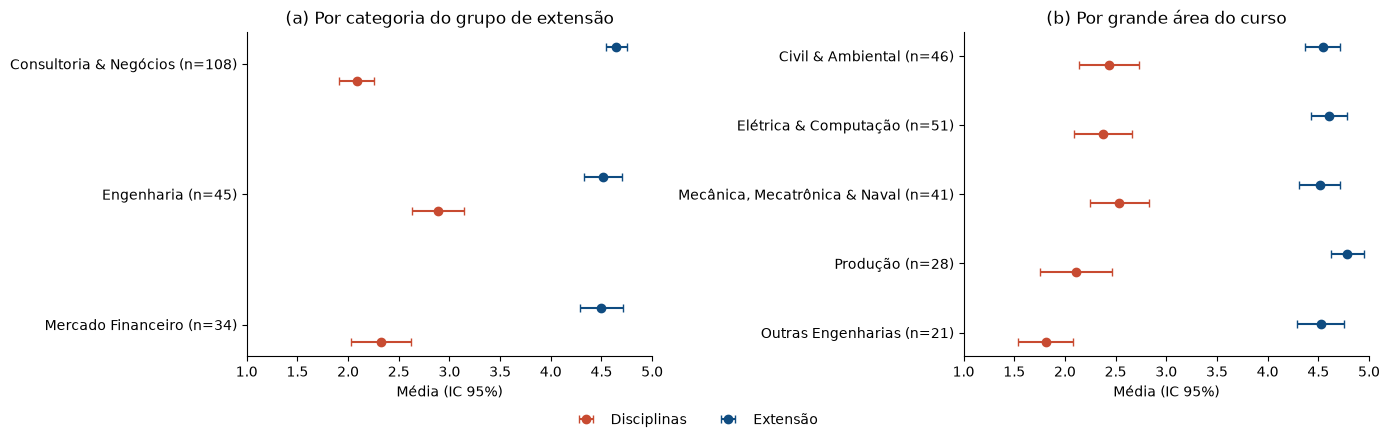

In [11]:
plot_preparo_by_category_and_area(df, CATEGORY_ORDER, AREA_ORDER, FIG_DIR / "f1_fig02_preparo_por_categoria_e_area.png")

**(c) Resultado.**

1. **Categoria e área são fortemente associadas:** χ²(8) = 69,3, p < 0,001, V de Cramér = 0,43, acima da referência de associação forte (0,35 para $k = 2$). A condição do teste é atendida (7% das caselas com esperado abaixo de 5; menor esperado = 3,8). Os grupos de Engenharia não têm alunos de Civil & Ambiental nem de Produção, e reúnem 25 dos 41 alunos de Mecânica, Mecatrônica & Naval.
2. **ANOVA do ganho líquido:**
   - **área:** sozinha é significativa (p = 0,038), mas controlada a categoria deixa de ser (F parcial(4; 180) = 1,99; p = 0,098; η² parcial = 0,04);
   - **categoria:** continua significativa controlada a área (F parcial(2; 180) = 10,25; p < 0,001; η² parcial = 0,10).
   - O mesmo padrão aparece no preparo nas disciplinas (categoria p < 0,001; área p = 0,065).
   - No preparo na extensão, nenhum dos fatores é significativo (p = 0,24 e 0,32).
   - O teste de Bartlett não rejeita variâncias iguais, nem no ganho (p = 0,61 por categoria e 0,31 por área) nem nas disciplinas (p = 0,72 e 0,14).
3. **Médias por categoria e Scheffé:**
   - **disciplinas:** Engenharia 2,89, Mercado Financeiro 2,32 e Consultoria & Negócios 2,08;
   - **extensão:** 4,51, 4,50 e 4,65, respectivamente;
   - **ganho líquido:** Consultoria & Negócios supera Engenharia em 0,94 ponto (IC de Scheffé: 0,46 a 1,43). Mercado Financeiro fica entre as duas, sem diferença significativa;
   - **disciplinas no Scheffé:** Engenharia dá nota 0,81 maior que Consultoria (IC 0,41 a 1,20) e 0,57 maior que Mercado Financeiro (IC 0,06 a 1,07). Na tabela, a primeira comparação aparece como "Consultoria − Engenharia = −0,81".

**(d)** Figura `f1_fig02`, tabelas `f1_tab03` a `f1_tab06`.

**(e) Conclusão para o relatório.** As diferenças de ganho entre cursos parecem refletir, em boa parte, a composição dos grupos de extensão. Área e categoria são fortemente associadas (χ², p < 0,001; V = 0,43): os grupos técnicos reúnem alunos de Elétrica, Computação e Mecânica. Controlada a categoria, a área deixa de ser significativa (p = 0,10); controlada a área, a categoria continua significativa (p < 0,001). Como os dois fatores se sobrepõem muito, os dados não separam totalmente os dois efeitos. Os membros de grupos técnicos (Thunder Ratz, Poli Racing) têm ganho cerca de 0,9 ponto menor que os de Consultoria & Negócios. Não há evidência de que valorizem menos a extensão (p = 0,24); a diferença está na avaliação das disciplinas, maior entre eles (2,89 contra 2,08).

## 5. P4 — Intensidade (horas semanais) ou tempo de casa (tempo no grupo)?

**(a) Pergunta e hipóteses.** O preparo percebido na extensão se associa à dedicação semanal, ao tempo de permanência no grupo ou aos dois?

- **Teste de associação** (um para cada variável):
  - $H_0$: dar nota máxima (5) à extensão é independente das horas semanais (ou do tempo no grupo);
  - $H_1$: há associação.
- **ANOVA de 2 fatores** (horas + tempo) sobre a nota de preparo na extensão:
  - $H_0$: médias iguais entre os níveis do fator, dado o outro fator;
  - $H_1$: ao menos uma difere.

**(b) Teste e premissas.**

- **Teste principal: qui-quadrado.** Como 64% dos alunos deram nota 5 (efeito teto), a pergunta natural é "quem dá a nota máxima?". O teste não exige variâncias iguais, e suas condições são atendidas: horas com 0% das caselas abaixo de 5; tempo com 12%, abaixo do limite de 20%.
- **ANOVA de 2 fatores: evidência complementar.** Horas e tempo de grupo aparecem juntos de formas diferentes nos alunos (tabela cruzada abaixo), e a ANOVA separa o efeito de cada um controlando o outro. Mas o teste de Bartlett **rejeita** variâncias iguais entre as faixas de horas, e no tempo de grupo ele nem pode ser calculado: o grupo "Mais de 2 anos" tem variância zero, porque todos deram nota 5.
  - Isso é consequência do teto: quanto mais horas, mais notas 5 e menos variação.
  - Por isso, a ANOVA aqui só confirma o qui-quadrado; não serve de prova isolada.

In [12]:
print("Contagens: horas semanais × deu nota 5 à extensão")
display(chi_square_association(df, "horas_semanais_grupo", "preparo_ext_maximo")[0])
p4_chi2 = chi_square_table(df, {"horas_semanais_grupo": "Horas semanais no grupo", "tempo_grupo": "Tempo no grupo"},
                           "preparo_ext_maximo")
p4_chi2.to_csv(TAB_DIR / "f1_tab07_p4_qui_quadrado.csv")
p4_chi2

Contagens: horas semanais × deu nota 5 à extensão


preparo_ext_maximo,Nota 3 ou 4,Nota 5
horas_semanais_grupo,,
1 a 5h,13,8
6 a 10h,21,22
11 a 20h,23,26
21 a 40h,8,40
Mais de 40h,3,23


,Qui-quadrado (χ²),Graus de liberdade,p-valor,"V de Cramér (0 = nenhuma, 1 = total)",Menor frequência esperada,% de caselas com esperado < 5,Decisão (α = 5%)
Variável testada,,,,,,,
Horas semanais no grupo,26.15,4,2.9e-05,0.374,7.64,0%,Rejeita H0
Tempo no grupo,7.37,3,0.0611,0.198,3.64,12%,Não rejeita H0


In [13]:
print("Contagens: tempo no grupo × horas semanais")
display(pd.crosstab(df["tempo_grupo"], df["horas_semanais_grupo"]))
p4_anova = two_way_anova(df, "preparo_extensao", "horas_semanais_grupo", "tempo_grupo", FACTOR_LABELS)
p4_anova.to_csv(TAB_DIR / "f1_tab08_p4_anova_2_fatores.csv")
display(p4_anova)
print("Teste de Bartlett — preparo na extensão")
bartlett_table(df, "preparo_extensao", {"horas_semanais_grupo": "Horas semanais no grupo", "tempo_grupo": "Tempo no grupo"})

Contagens: tempo no grupo × horas semanais


horas_semanais_grupo,1 a 5h,6 a 10h,11 a 20h,21 a 40h,Mais de 40h
tempo_grupo,,,,,
Menos de 6 meses,3,8,1,1,2
6 meses a 1 ano,14,18,27,18,7
1 a 2 anos,4,16,18,27,13
Mais de 2 anos,0,1,3,2,4


,p sozinho (ANOVA 1 fator),F parcial (controlando o outro fator),gl,p parcial,η² parcial,Decisão (α = 5%)
Fator,,,,,,
Horas semanais no grupo,6.9e-06,7.79,4; 179,8.2e-06,0.148,Rejeita H0
Tempo no grupo,0.0603,2.49,3; 179,0.0618,0.040,Não rejeita H0


Teste de Bartlett — preparo na extensão


,Bartlett (χ²),p Bartlett,Variâncias homogêneas?
Grupos comparados,,,
Horas semanais no grupo,25.96,3.2e-05,Não (rejeita H0)
Tempo no grupo,NaN,NaN,Não calculável: há grupo com variância zero


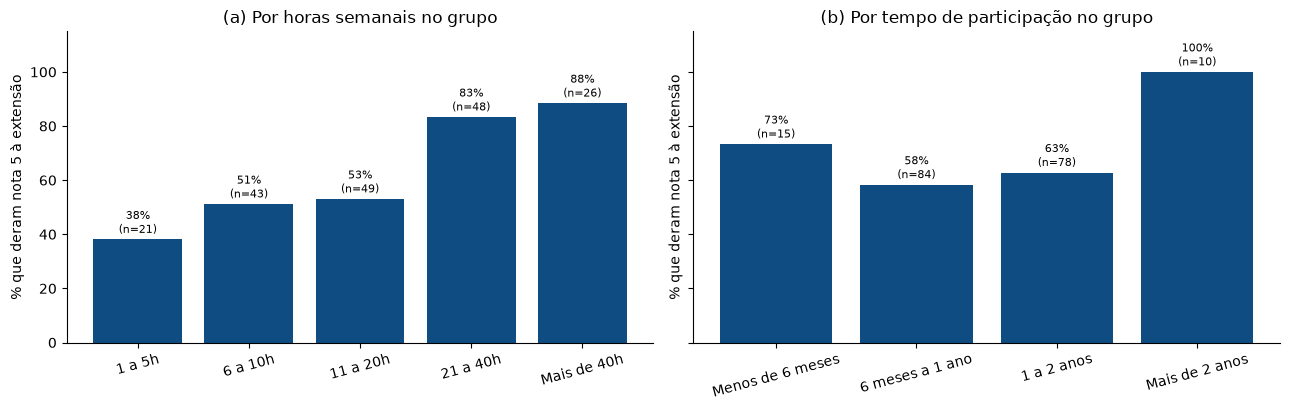

In [14]:
plot_top_score_share(df, [("horas_semanais_grupo", HOURS_ORDER, "(a) Por horas semanais no grupo"),
                          ("tempo_grupo", TIME_ORDER, "(b) Por tempo de participação no grupo")],
                     FIG_DIR / "f1_fig03_nota_maxima_por_horas_e_tempo.png")

**(c) Resultado.**

- **Horas semanais:** associação significativa com dar nota máxima. χ²(4) = 26,15, p < 0,001, V de Cramér = 0,37 (moderada; referência 0,30 a 0,50 para $k = 1$).
  - A proporção de nota 5 sobe de 38% (1–5 h) para 51–53% (6–20 h) e 83–88% (mais de 20 h).
  - Somando as duas faixas acima de 20 h, são 63 de 74 alunos, ou 85% (40 + 23 de 48 + 26, na tabela de contagens).
- **Tempo no grupo:** associação não significativa. χ²(3) = 7,37, p = 0,061, V = 0,20.
  - Os 10 alunos com mais de 2 anos deram todos nota 5, mas o grupo é pequeno e provavelmente sofre viés de sobrevivência (quem não gosta sai antes).
- **ANOVA de 2 fatores (complementar):**
  - horas continuam significativas controlando o tempo (F parcial(4; 179) = 7,79; p < 0,001; η² parcial = 0,15);
  - tempo não é significativo controlando as horas (F parcial(3; 179) = 2,49; p = 0,062).
  - Mesma conclusão do qui-quadrado, com a ressalva das variâncias desiguais.

**(d)** Figura `f1_fig03`, tabelas `f1_tab07` e `f1_tab08`.

**(e) Conclusão para o relatório.** O que se associa à percepção de preparo na extensão é a intensidade da dedicação. Entre quem dedica mais de 20 h por semana, 85% dão nota máxima, contra 38% de quem dedica até 5 h (χ², p < 0,001). Não encontramos evidência de associação com o tempo de permanência no grupo (p = 0,06), nem quando se controlam as horas. Os dados não dizem a direção causal: mais horas podem gerar mais aprendizado, ou quem percebe mais retorno pode escolher dedicar mais horas.

## 6. P6 — O objetivo atual na faculdade se associa à importância dada à média?

**(a) Pergunta e hipóteses.** Seja $\mu_j$ a média da importância da média ponderada (escala 1–5) entre os alunos com objetivo $j$.

- $H_0$: $\mu_{\text{Grupo}} = \mu_{\text{Estágio}} = \mu_{\text{Desempenho}} = \mu_{\text{Intercâmbio}} = \mu_{\text{Iniciação científica}}$;
- $H_1$: ao menos uma média difere.

**(b) Teste e premissas.** ANOVA de 1 fator (n = 180, sem os 7 objetivos não agrupáveis), com teste de Bartlett para as variâncias e contrastes de Scheffé.

- **Contrastes de Scheffé:** todos os 10 pares de objetivos, mais um contraste-resumo, que é a média simples das médias de {Intercâmbio, Iniciação científica, Desempenho} menos a de {Grupo, Estágio}. Scheffé permite contrastes escolhidos depois de olhar os dados.
- **Cuidados:**
  - "Iniciação científica" tem só 6 alunos, então sua média tem IC largo;
  - a categoria "Desempenho acadêmico (manter/elevar a média)" fala da própria média, então sua alta importância é esperada. O achado relevante está em Intercâmbio e Iniciação científica.

In [15]:
df_objetivo = df.dropna(subset=["objetivo_faculdade"])
p6 = one_way_anova(df_objetivo, "importancia_media", "objetivo_faculdade",
                   title="ANOVA de 1 fator: importância da média por objetivo atual")
p6.to_csv(TAB_DIR / "f1_tab09_p6_anova.csv")
p6

,ANOVA de 1 fator: importância da média por objetivo atual
F,15.82
gl (fator; resíduo),4; 175
p-valor,4.5e-11
η² (variância explicada),0.266
Decisão (α = 5%),Rejeita H0
Bartlett (χ²),3.78
p Bartlett,0.4369
Variâncias homogêneas?,Sim (não rejeita H0)


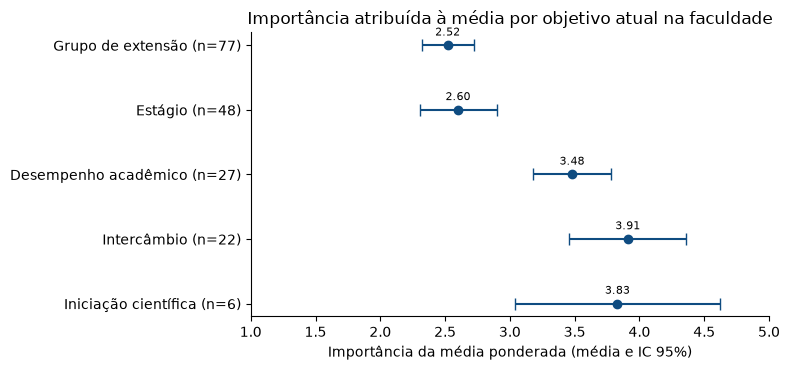

,n,Média,Desvio-padrão,IC 95% inf,IC 95% sup
Objetivo atual,,,,,
Grupo de extensão,77,2.52,0.87,2.32,2.72
Estágio,48,2.60,1.01,2.31,2.90
Desempenho acadêmico,27,3.48,0.75,3.18,3.78
Intercâmbio,22,3.91,1.02,3.46,4.36
Iniciação científica,6,3.83,0.75,3.04,4.62


In [16]:
p6_means = group_means(df_objetivo, "importancia_media", "objetivo_faculdade", "Objetivo atual")
plot_goal_means(p6_means, GOAL_ORDER, FIG_DIR / "f1_fig04_importancia_media_por_objetivo.png")
p6_means

In [17]:
p6_scheffe = scheffe_contrasts(df_objetivo, "importancia_media", "objetivo_faculdade", contrasts=GOAL_CONTRASTS)
p6_scheffe.to_csv(TAB_DIR / "f1_tab10_p6_scheffe.csv")
p6_scheffe

,Estimativa (diferença),IC 95% de Scheffé,p de Scheffé,Significativo?
Contraste,,,,
Desempenho acadêmico − Grupo de extensão,0.96,[0.33; 1.59],2.8e-04,Sim
Desempenho acadêmico − Estágio,0.88,[0.20; 1.56],0.0037,Sim
Intercâmbio − Grupo de extensão,1.39,[0.71; 2.07],2.5e-07,Sim
Intercâmbio − Estágio,1.30,[0.58; 2.03],8.3e-06,Sim
Iniciação científica − Grupo de extensão,1.31,[0.12; 2.51],0.0228,Sim
Iniciação científica − Estágio,1.23,[0.01; 2.45],0.0482,Sim
Grupo de extensão − Estágio,-0.08,[-0.60; 0.43],0.9923,Não
Intercâmbio − Desempenho acadêmico,0.43,[-0.38; 1.24],0.6115,Não
Iniciação científica − Desempenho acadêmico,0.35,[-0.92; 1.63],0.9462,Não


**(c) Resultado.**

- **ANOVA:** F(4; 175) = 15,82, p < 0,001, η² = 0,27. O objetivo explica 27% da variação da importância dada à média. O teste de Bartlett não rejeita variâncias iguais (p = 0,44).
- **Médias:**
  - Grupo de extensão 2,52 e Estágio 2,60;
  - Desempenho acadêmico 3,48, Intercâmbio 3,91 e Iniciação científica 3,83 (IC de 3,04 a 4,62, com n = 6).
- **Scheffé:**
  - cada objetivo do bloco {Desempenho, Intercâmbio, Iniciação científica} difere de cada objetivo do bloco {Grupo, Estágio} (p ≤ 0,048; Estágio × Iniciação científica é o par mais próximo do limite);
  - nenhum dos 4 pares dentro dos blocos difere (p ≥ 0,61);
  - o contraste-resumo é de 1,18 ponto (IC de Scheffé: 0,64 a 1,72).

**(d)** Figura `f1_fig04`, tabelas `f1_tab09` e `f1_tab10`.

**(e) Conclusão para o relatório.** O objetivo atual se associa fortemente à importância dada à média ponderada (ANOVA, p < 0,001; η² = 0,27). Os alunos se dividem em dois blocos. Quem mira intercâmbio (3,91), iniciação científica (3,83) ou desempenho acadêmico (3,48) atribui, em média, cerca de 1,2 ponto a mais de importância à média do que quem foca no grupo de extensão (2,52) ou no estágio (2,60). Isso é coerente com seleções de intercâmbio e de iniciação científica que usam a média como critério, enquanto estágio e grupo de extensão valorizam outras competências.

## 7. Modelo explicativo — regressão linear múltipla do ganho líquido

**(a) Objetivo e hipóteses.** A P2+P3 mostrou que a categoria do grupo se associa ao ganho líquido; a P4 mostrou que as horas se associam ao preparo na extensão. A regressão junta os fatores num só modelo para:

- estimar a **associação de cada fator com o ganho, mantidos os demais constantes** (os coeficientes β);
- verificar, pelo **F parcial**, se outras variáveis conhecidas *a priori* acrescentam algo;
- **comparar perfis definidos de antemão**, como "aluno de grupo técnico com 6–10 h". Isso serve para orientar um calouro que esteja escolhendo grupo e dedicação, lembrando que os β descrevem associações observadas, não efeitos garantidos.

O foco é **explicativo, não preditivo**. Em pesquisas de opinião, modelos lineares raramente preveem bem o valor de cada pessoa; o que interessa é o sinal, o tamanho e a significância dos β.

Para cada variável candidata, as hipóteses são:

- $H_0$: os β dessa variável são todos zero (ela não acrescenta nada, dadas as demais);
- $H_1$: algum β é diferente de zero.

**Modelo completo, com base teórica.** A resposta é o ganho líquido. As variáveis candidatas são:

- categoria do grupo (P2+P3);
- grande área do curso (P2+P3);
- horas semanais (P4);
- tempo no grupo (P4);
- tempo de deslocamento de casa à Poli, em minutos (restrição de rotina que poderia limitar a vivência no grupo).

$$\text{ganho}_i = \beta_0 + \sum \beta_{\text{cat}}\,\text{categoria}_i + \sum \beta_{\text{área}}\,\text{área}_i + \beta_h \ln(\text{horas}_i) + \sum \beta_{\text{tempo}}\,\text{tempo}_i + \beta_{\text{desl}}\,\text{deslocamento}_i + \varepsilon_i$$

> **Conceito — variáveis categóricas na regressão.** Uma variável com vários níveis entra como **indicadoras 0/1**, uma para cada nível exceto o de referência. Por exemplo, a categoria tem 3 níveis e entra com 2 indicadoras (Engenharia e Mercado Financeiro), cada uma comparada à referência Consultoria & Negócios. Por isso, a categoria "gasta" 2 graus de liberdade, a área 4 e o tempo de grupo 3.

> **Conceito — eliminação por F parcial (princípio da parcimônia).** Parte-se do modelo completo. Em cada passo, testa-se cada variável com o F parcial ($H_0$: os β dessa variável são todos zero). A de maior p-valor sai se p ≥ 0,05, e o processo se repete até todas as restantes serem significativas. No fim, um F parcial conjunto confirma que o modelo reduzido não perde informação. O critério é o F parcial, não o R² ajustado.

**(b) Horas em logaritmo.** As horas entram pelo valor representativo de cada faixa (tabela abaixo). Esse valor veio do pré-processamento: é o valor esperado dentro da faixa segundo a distribuição lognormal ajustada pelo Pedro Salles, por isso "Mais de 40h" vale 70,4 h.

O ganho médio observado é quase plano até 20 h e sobe nas faixas altas. Em escala linear, o valor de 70 h ficaria muito distante dos demais e dominaria a inclinação. O logaritmo aproxima as faixas e permite uma leitura simples: **dobrar as horas corresponde a $\beta_h \cdot \ln 2 \approx 0{,}69\,\beta_h$ ponto de ganho**.

Para checar se um único coeficiente para ln(horas) basta, comparamos esse modelo com outro que usa as 5 faixas como fator (4 indicadoras), via F parcial (célula logo após a eliminação).

In [18]:
hours_band_table(df)

,Horas representativas (h/semana),ln(horas),Ganho líquido médio observado,n
Faixa de horas,,,,
1 a 5h,3.41,1.23,1.86,21
6 a 10h,7.46,2.01,1.70,43
11 a 20h,14.46,2.67,2.08,49
21 a 40h,28.00,3.33,2.77,48
Mais de 40h,70.36,4.25,2.96,26


In [19]:
elimination_steps, final_model, kept_variables = backward_elimination(df, "delta_preparo", REGRESSION_BLOCKS)
elimination_steps.to_csv(TAB_DIR / "f1_tab11_regressao_eliminacao_f_parcial.csv")
elimination_steps

,Nº de variáveis no modelo,Variável com maior p,F parcial,gl,p parcial,Decisão,R² ajustado
Passo,,,,,,,
1,5,Tempo no grupo,0.80,3; 175,0.4971,"Remover (p ≥ 0,05)",0.198
2,4,Tempo de deslocamento (min),1.51,1; 178,0.2215,"Remover (p ≥ 0,05)",0.201
3,3,Grande área do curso,1.89,4; 179,0.1147,"Remover (p ≥ 0,05)",0.199
4,2,Categoria do grupo,5.99,2; 183,0.0030,"Manter todas (p < 0,05)",0.183


In [20]:
full_model = fit_ols(df, "delta_preparo", REGRESSION_BLOCKS)
hours_as_factor = fit_ols(df, "delta_preparo", ["C(categoria_grupo)", "C(horas_semanais_grupo)"])
display(joint_partial_f_test(full_model, final_model, "Modelo completo vs. modelo final"))
display(joint_partial_f_test(hours_as_factor, final_model, "Horas como 5 faixas vs. ln(horas)"))
model_summary(final_model)

,Modelo completo vs. modelo final
F parcial,1.43
gl,8; 175
p-valor,0.1872
Decisão (α = 5%),Não rejeita H0 (modelo reduzido é suficiente)


,Horas como 5 faixas vs. ln(horas)
F parcial,1.49
gl,3; 180
p-valor,0.2185
Decisão (α = 5%),Não rejeita H0 (modelo reduzido é suficiente)


,Ajuste do modelo
n,187
R²,0.196
R² ajustado,0.183
F global,14.89
gl (modelo; resíduo),3; 183
p-valor do F global,1.0e-08
Erro-padrão residual,1.053


In [21]:
coefficients = coefficient_table(final_model, REGRESSION_LABELS)
coefficients.to_csv(TAB_DIR / "f1_tab12_regressao_coeficientes.csv")
coefficients

,β (estimativa),Erro-padrão,t,p-valor,IC 95% inf,IC 95% sup
"Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)",1.345,0.298,4.51,1.1e-05,0.757,1.933
Engenharia (vs. Consultoria & Negócios),-0.674,0.197,-3.43,7.6e-04,-1.063,-0.286
Mercado Financeiro (vs. Consultoria & Negócios),-0.139,0.215,-0.65,0.5192,-0.563,0.285
ln(horas semanais),0.404,0.093,4.35,2.2e-05,0.221,0.587


**De onde vem a associação com as horas?** O ganho é extensão − disciplinas. Por isso, o modelo final foi ajustado também para cada parte separadamente, com os mesmos preditores.

In [22]:
coefficients_by_response(df, DECOMPOSITION, ["C(categoria_grupo)", "log_horas_semanais"], REGRESSION_LABELS)

Ganho líquido  \
                                                                                                 β   
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)         1.345   
Engenharia (vs. Consultoria & Negócios)                                                     -0.674   
Mercado Financeiro (vs. Consultoria & Negócios)                                             -0.139   
ln(horas semanais)                                                                           0.404   

                                                                                               \
                                                                                      p-valor   
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)  1.1e-05   
Engenharia (vs. Consultoria & Negócios)                                               7.6e-04   
Mercado Financeiro (vs. Consultoria & Negócios)                                        0.5192   
ln(horas semanais)                                                                    2.2e-05   

                                                                                     Preparo nas disciplinas  \
                                                                                                           β   
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)                   2.585   
Engenharia (vs. Consultoria & Negócios)                                                                0.695   
Mercado Financeiro (vs. Consultoria & Negócios)                                                        0.137   
ln(horas semanais)                                                                                    -0.166   

                                                                                               \
                                                                                      p-valor   
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)  7.5e-20   
Engenharia (vs. Consultoria & Negócios)                                               4.4e-05   
Mercado Financeiro (vs. Consultoria & Negócios)                                        0.4494   
ln(horas semanais)                                                                     0.0351   

                                                                                     Preparo na extensão  \
                                                                                                       β   
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)               3.930   
Engenharia (vs. Consultoria & Negócios)                                                            0.021   
Mercado Financeiro (vs. Consultoria & Negócios)                                                   -0.001   
ln(horas semanais)                                                                                 0.238   

                                                                                               
                                                                                      p-valor  
Intercepto (Consultoria & Negócios com 1 h/semana; fora dos dados, só ancora a reta)  1.1e-61  
Engenharia (vs. Consultoria & Negócios)                                                0.8392  
Mercado Financeiro (vs. Consultoria & Negócios)                                        0.9907  
ln(horas semanais)                                                                    2.0e-06

**Por que o efeito de grupo técnico é −0,94 na P2+P3 e −0,67 aqui?** Na P2+P3, comparamos as médias brutas das categorias. Aqui, as horas estão controladas, e os membros de grupos técnicos dedicam menos horas: 44% estão na faixa de 6–10 h, contra 12% em Consultoria & Negócios. Parte da diferença bruta acompanha essa menor dedicação.

In [23]:
hours_share_by_category(df)

Horas semanais (% da categoria),1 a 5h,6 a 10h,11 a 20h,21 a 40h,Mais de 40h
Categoria do grupo,,,,,
Consultoria & Negócios,5.0,12.0,31.0,37.0,16.0
Engenharia,11.0,44.0,27.0,16.0,2.0
Mercado Financeiro,32.0,29.0,12.0,3.0,24.0


**Verificação das premissas (resíduos).** A regressão supõe resíduos com média zero, variância constante e distribuição aproximadamente normal.

- **Gráfico (a):** como o modelo final só tem categoria (3 níveis) e faixa de horas (5 valores), há apenas 15 valores ajustados diferentes. Os pontos formam colunas verticais, levemente deslocadas na horizontal para não se sobreporem. Em cada coluna, os resíduos se espalham em torno de zero, sem funil evidente.
- **Gráfico (b):** os pontos seguem a reta, o que indica normalidade aproximada. Os degraus aparecem porque o ganho só assume valores inteiros.
- **Ressalva:** o ganho é discreto (de −1 a 4) e limitado, então a regressão linear é uma aproximação, aceitável para um modelo explicativo.

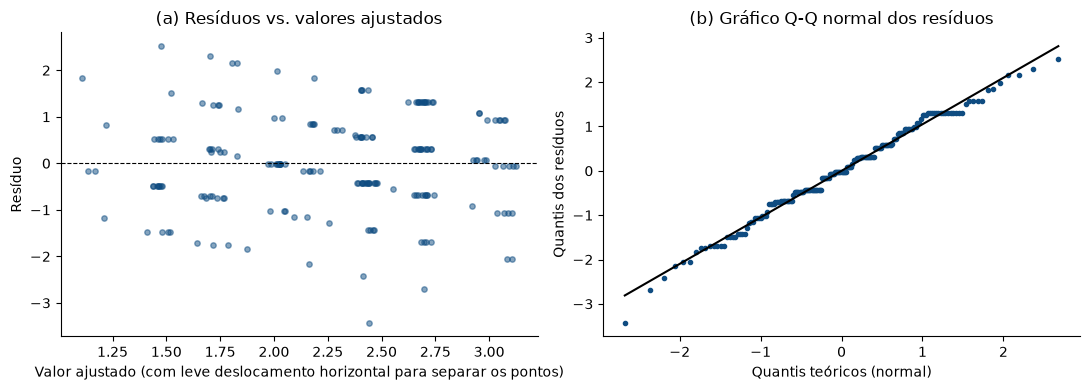

In [24]:
plot_residual_diagnostics(final_model, FIG_DIR / "f1_fig05_regressao_residuos.png")

**Aplicação: comparação de perfis definidos a priori.**

- O **valor estimado** é o ganho médio dos alunos com o perfil.
- O **IC 95% da média** mostra onde está a média desse perfil.
- O **IP 95% individual** (intervalo de predição) mostra onde deve cair um aluno específico. Ele é bem mais largo, e alguns limites passam de 4, o máximo possível do ganho, efeito da aproximação linear. Isso deixa claro que o modelo compara perfis, mas não prevê pessoas.

In [25]:
scenarios = predict_scenarios(final_model, build_scenarios(df, hours_bands=("6 a 10h", "21 a 40h")))
scenarios.to_csv(TAB_DIR / "f1_tab13_regressao_cenarios.csv")
scenarios

,Valor estimado (média do perfil),IC 95% da média,IP 95% individual
Cenário,,,
"Consultoria & Negócios, 6 a 10h",2.16,[1.88; 2.43],[0.06; 4.25]
"Consultoria & Negócios, 21 a 40h",2.69,[2.48; 2.90],[0.60; 4.78]
"Engenharia, 6 a 10h",1.48,[1.17; 1.80],[-0.62; 3.59]
"Engenharia, 21 a 40h",2.02,[1.66; 2.38],[-0.09; 4.13]
"Mercado Financeiro, 6 a 10h",2.02,[1.65; 2.38],[-0.09; 4.13]
"Mercado Financeiro, 21 a 40h",2.55,[2.16; 2.95],[0.44; 4.67]


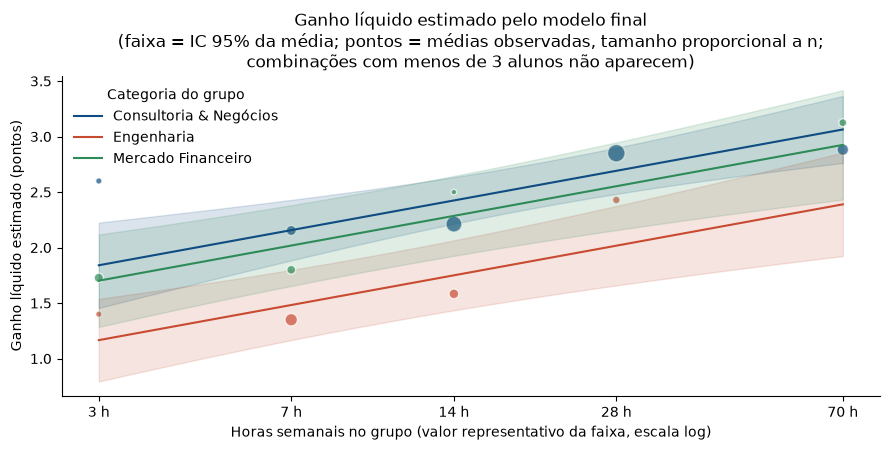

In [26]:
plot_regression_scenarios(final_model, df, CATEGORY_ORDER, FIG_DIR / "f1_fig06_regressao_cenarios.png")

**(c) Resultado.**

- **Eliminação por F parcial** (tabela `f1_tab11`), nesta ordem:
  1. sai o tempo no grupo (p = 0,50);
  2. sai o tempo de deslocamento (p = 0,22);
  3. sai a grande área do curso (p = 0,11);
  4. ficam a categoria do grupo (p = 0,003) e as horas.
- **Testes de suficiência:**
  - o F parcial conjunto confirma que o modelo reduzido basta (F(8; 175) = 1,43; p = 0,19);
  - usar as 5 faixas de horas em vez de ln(horas) não melhora o ajuste (F(3; 180) = 1,49; p = 0,22).
- **Modelo final:** R² = 0,20 (ajustado 0,18), F global(3; 183) = 14,9, p < 0,001.
- **Coeficientes:**
  - **ln(horas):** β = 0,40 (IC 95%: 0,22 a 0,59; p < 0,001). Quem dedica o dobro de horas tem, em média, ganho cerca de **0,28 ponto maior**, mantida a categoria.
    - Ao separar as partes: maior preparo na extensão (β = +0,24; p < 0,001) e menor nota às disciplinas (β = −0,17; p = 0,035).
    - Cerca de 60% da associação vem da extensão e 40% das disciplinas.
  - **Engenharia:** β = −0,67 (IC 95%: −1,06 a −0,29; p < 0,001). Com as mesmas horas, membros de grupos técnicos têm ganho 0,67 ponto menor que os de Consultoria & Negócios. Pela decomposição, essa diferença está inteiramente nas disciplinas (+0,70; p < 0,001); na extensão, é +0,02 (p = 0,84).
  - **Mercado Financeiro:** não difere de Consultoria & Negócios (p = 0,52).
- **Perfis:**
  - Consultoria & Negócios com 21–40 h: ganho médio estimado de 2,69 (IC 95%: 2,48 a 2,90);
  - grupo técnico com 6–10 h: 1,48 (IC 95%: 1,17 a 1,80);
  - o intervalo de predição individual tem cerca de ±2,1 pontos.

**(d)** Figuras `f1_fig05` e `f1_fig06`, tabelas `f1_tab11` a `f1_tab13`.

**(e) Conclusão para o relatório.** Das cinco candidatas escolhidas pela teoria, o F parcial manteve só a categoria do grupo e as horas semanais. Área do curso, tempo no grupo e tempo de deslocamento não acrescentam informação significativa (p = 0,19 no teste conjunto). Mantida a categoria, quem dedica o dobro de horas tem ganho cerca de 0,28 ponto maior: mais preparo percebido na extensão e nota um pouco menor às disciplinas. Mantidas as horas, membros de grupos técnicos têm ganho 0,67 ponto menor, inteiramente por avaliarem melhor as disciplinas. O modelo explica 20% da variação. Serve para comparar perfis, como a escolha de grupo e de dedicação de um calouro, mas não para prever a resposta de um aluno específico.

## 8. Síntese da frente

1. **A extensão é vista como a principal fonte de preparo profissional, de forma quase unânime** (P1).
2. **As diferenças entre cursos parecem refletir, em boa parte, a composição dos grupos de extensão.** Quem varia é a avaliação das disciplinas: grupos técnicos a valorizam mais e, por isso, têm ganho líquido menor (P2+P3).
3. **Dentro da extensão, pesa a intensidade.** As horas semanais se associam ao preparo percebido; não encontramos associação com o tempo de casa (P4).
4. **A importância dada à média se associa ao objetivo.** É alta para quem mira intercâmbio, iniciação científica ou desempenho, e baixa para quem foca no grupo ou no estágio (P6).
5. **O modelo explicativo junta os achados 2 e 3** e quantifica cada associação: −0,67 ponto para grupos técnicos e +0,28 ponto para o dobro de horas (regressão).

**Nota sobre múltiplos testes.** Os 10 testes principais da frente são:

- P1: t pareado;
- P2+P3: qui-quadrado, F parcial da categoria e F parcial da área;
- P4: qui-quadrado das horas e do tempo;
- P6: ANOVA;
- regressão: F parcial conjunto, β das horas e β da categoria.

Os significativos têm p ≤ 0,003, abaixo do limite de Bonferroni (α / número de testes = 0,05 / 10 = 0,005). Continuam significativos mesmo com essa correção, que é a mais conservadora. Os não significativos (área controlada pela categoria, p = 0,10; tempo de grupo, p = 0,06) já não o eram sem correção.

## 9. Limitações

1. **Sem grupo de comparação.** Todos os respondentes são de extensão, então os resultados são associações e percepções entre participantes, não efeitos causais. Há provável viés de seleção e de sobrevivência: quem valoriza a extensão entra, permanece e responde.
2. **Amostra por conveniência,** com a Poli Júnior em 40% das respostas (75 de 187). Grupos de outros perfis (sociais, de pesquisa, culturais) não estão representados.
3. **Escalas de item único e autoavaliação.** Pode haver viés de desejabilidade social, e o "preparo profissional" não foi medido de forma objetiva.
4. **Efeito teto** na nota de preparo na extensão. Isso reduz a variabilidade dessa nota e explica as variâncias desiguais da P4.
5. **Grupos pequenos:** Iniciação científica (n = 6) e o grupo de mais de 2 anos de casa (n = 10) têm estimativas imprecisas.
6. **Desenho transversal.** Não acompanha os mesmos alunos ao longo do tempo, então não dá para afirmar que a percepção muda com a permanência.